In [1]:
# Verplicht: Voer hier je studentnaam en student in van je duo.
# Als je dit niet invult krijg je geen voldoende voor het vak

# Door dit in te vullen en onderaan de boolean op True te zetten
# beloof je als duo dit alleen met z'n twee te maken.
# Je gebruikt geen code van andere studenten. 
# Gebruik van ChatGPT, andere taalmodellen 
# of taalmodellen gemaakt voor code schrijven is verboden!
# Je moet dus laten zien dat je dit ZELF kunt door lopen.
# Als je als duo echt niet verder komt vraag dan de docent om hulp!
# Overtreding van een van deze spelregels kan lijden tot een 
# onvoldoende voor het hele vak.

student_naam_1 = "Charise Walraven"
student_naam_2 = "Tim van Veenhuijzen"

student_id_1 = "1008575"
student_id_2 = "1097946"

wij_beloven_geen_fraude_te_plegen = True # Maak hier True van!

# Einopdracht deel 2

In het tweede deel van de eindopdracht van programmeren 4 gaan we van een verzameling losse experimentjes naar een volledig neuraal netwerk. We beginnen het het verzamelen van al onze stukjes code.

In [2]:
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Qt5Agg')
import matplotlib.pyplot as plt
%matplotlib inline

In deel 1 van de opdracht was onze geheime functie, die we door ons model lieten oplossen, een lineaire functie. Dit was $20x+50$ plus wat ruis. De echte wereld, en data uit de echte wereld is alles behalve lineair, dus we gaan het iets moeilijker maken voor ons model. We gebruiken voor nu de formule $20x^2 + 50$ inclusief wat ruis.

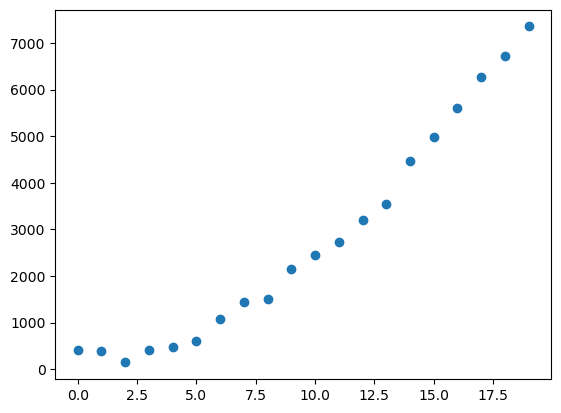

In [3]:
train_size = 20
x = np.arange(train_size).reshape(-1,1)
y = ( 20* x ** 2 + 50
     + (np.random.randint(0, 500, size=train_size)
                 .reshape(-1,1)))
plt.scatter(x, y)
plt.show()

### TODO 1: Kopieer de oude code
    Vul alle #TODO stukjes in de code hieronder met de code uit opdracht deel 1.

In [4]:
def plot_model(x, y, model=None):
    # TODO: Plak hier de code van de tweede plot functie
    fig, ax = plt.subplots()
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    
    ax.scatter(x, y)
    
    if model is not None:
        ax.scatter(x, model.forward(x), marker='+')
    plt.show()

def abs(x):
    return np.abs(x)

def mae(x, y, model):
    # TODO: Plak hier de code van je MAE functie
    mae_score = np.mean(abs(model.forward(x) - y)) 
    return mae_score

def abs_d(x):
    # TODO: Plak hier de code van je absoluut afgeleide functie
    a = np.array([1 if v else -1 for v in x > 0])
    return a
    

class LinearModel:
    # TODO: Plak hier je code (twee functies/methode) uit je linearmodel class
    def __init__(self, a, b):
        self.a = a
        self.b = b
    def forward(self, x):
        return self.a * x + self.b
    

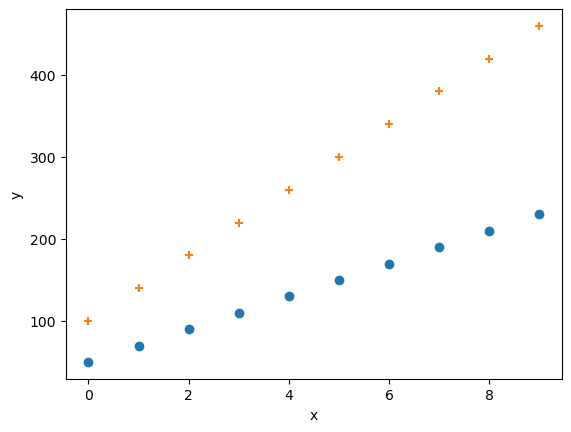

Als dit print heb je het waarschijnlijk goed gedaan.


In [5]:
# Hier gaan we de todo 1 testen 
linear_model = LinearModel(15, 19)
assert linear_model.a == 15
assert linear_model.b == 19

linear_model = LinearModel(15, 2)
assert linear_model.forward(107) == 1607
assert linear_model.forward(30) == 452

# Test with arrays too (critical for neural network!)
test_x = np.array([[0], [1], [2]])
expected = np.array([[2], [17], [32]])  # 15*x + 2
result = linear_model.forward(test_x)
assert np.array_equal(result, expected), f"Expected {expected}, got {result}"

# MAE tests with tolerance
x_test = np.arange(10).reshape(-1,1)
y_test = (20 * x_test + 50).reshape(-1,1)

linear_model = LinearModel(10, 3)
assert np.isclose(mae(x_test, y_test, linear_model), 92, rtol=1e-10)

linear_model = LinearModel(40, 100)
assert np.isclose(mae(x_test, y_test, linear_model), 140, rtol=1e-10)

# abs_d tests with proper numpy comparison
assert np.array_equal(abs_d(np.array([1])), np.array([1]))
assert np.array_equal(abs_d(np.array([-1])), np.array([-1]))
assert np.array_equal(abs_d(np.array([-102])), np.array([-1]))
assert np.array_equal(abs_d(np.array([164])), np.array([1]))

# Test multiple elements
assert np.array_equal(abs_d(np.array([1, -1, 5, -3])), 
                        np.array([1, -1, 1, -1]))

plot_model(x_test, y_test, linear_model)
plt.show()
print("Als dit print heb je het waarschijnlijk goed gedaan.")

## Ons probleem

Om nog even te laten zien waar we nu tegen aan lopen. Onze data is non-lineair. Waarom? Omdat $x^2$, zoals we onze data hebben gegenereerd, per definitief niet linear is. Als we het plotten zien we ook dat er geen lijn door heen te trekken is. We kunnen dat makkelijk laten zien. Je mag de twee parameters (nu 300 en 50) zo veel aanpassen als je wilt. Maar je zult zien dat je altijd een deel van de data overschat en een ander deel onderschat. 

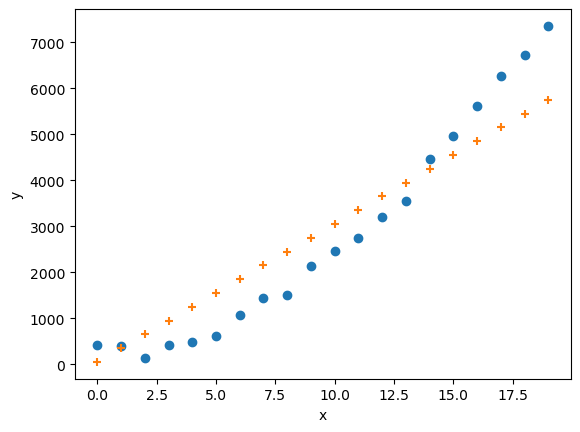

In [6]:
plot_model(x, y, LinearModel(300, 50))

## De oplossing

Onze oplossing gaat zijn, een volledig neuraal netwerk. En dat is in twee opzichten anders dan wat wij in deel 1 hebben gemaakt.

De eerste. Een neuraal netwerk bestaat uit meerdere lineaire modellen. Je kunt dit inbeelden bij de bovenstaande grafiek. Stel dat je meerdere lijntjes trekt die op meerdere plekken tegen de data aan zit. Want hoe meer je op de data inzoomt, hoe vlakker, of meer lineair het is.

Als we veel van deze lineaire modellen optellen, dan is het resultaat weer een lineair model. Dus meerdere van die lijntjes worden dan 1 grote lijn. En zoals we net zagen, we kunnen geen lijn trekken door onze data. 

De oplossing is het tweede onderdeel van een neuraal netwerk. We willen een mechanisme waarmee we de lineaire modellen kunnen aan en uit zetten. Dus dat 1 lineair model een lijn kan trekken in de data van $x$ tussen $0$ en $2.5$, hier is de data redelijk vlak. En dat we een ander model trainen op $2.5$ tot $5.0$. De truc hiervoor is iets wat we noemen: een activatie functie. De output van elk lineair model stoppen we in een activatie functie. Hierdoor kan het lineair model zichzelf trainen om soms geen output te geven. Dit is net zoals in het brein, soms gaat een neuron vuren (elektrisch signaal doorgeven) en soms niet $^1$. 


<sub>1: in het echt stoppen neuronen nooit met vuren, maar ze coderen informatie door langzamer of sneller te vuren</sub>


Er bestaan veel type activatie functies, maar de meest gebruikte, en de meest simpele is de ReLu funtie. Dit staat voor rectified linear unit. Veel moeilijke woorden voor een simpel dingetje. Het is namelijk gedefinieerd als $f(x) = max(0, x)$. In het Nederlands: als x groter is dan nul, geef x terug, anders geef 0 terug. Laten we dit programmeren:


### TODO 2: Programmeer de relu functie

In [7]:
def relu(x):
    # TODO: geef de relu terug van x. Gebruik de numpy (np.maximum) functie.
    return np.maximum(0, x)

In [8]:
assert np.array_equal(relu(np.array([-10, -1, 0, 1, 2, 3, 4])), 
                         np.array([0, 0, 0, 1, 2, 3, 4]))
assert np.array_equal(relu(np.array([-5])), np.array([0]))
assert np.array_equal(relu(np.array([-1.5, 0.0, 2.7])), 
                         np.array([0.0, 0.0, 2.7]))
print("Als dit print is het waarschijnlijk goed. Maar check het zelf ook altijd!")

Als dit print is het waarschijnlijk goed. Maar check het zelf ook altijd!


### ReLu

Laten we nu kijken hoe dit er uit ziet.

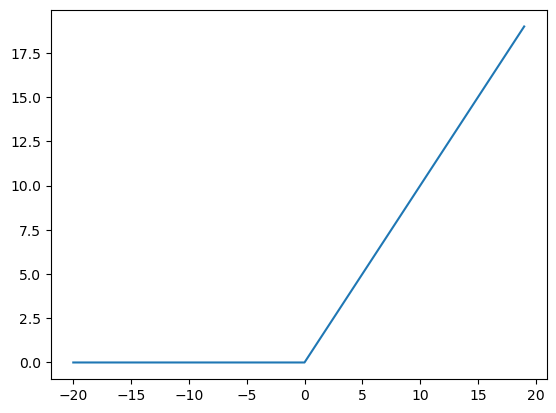

In [9]:
x_test = np.arange(-20, 20)
plt.plot(x_test, relu(x_test))
plt.show()

Wat we zien is de typische ReLu vorm. Als $x$ kleiner is dan 0 dan is $y$ ook 0. Deze ReLu stop je om de lineaire vergelijking heen. Dus de output van je lineair model gaat door de ReLu heen. Laten we kijken of dat ons lukt:

### TODO 3: Maak je non-lineair model

In [10]:
class NonLinearModel:
    # TODO: Stap 1 plak hier de code van je LinearModel class
    # TODO: Stap 2, schrijf de relu functie om je lineaire vergelijking heen
    # dit zal iets zijn als relu(a*x+b)
    def __init__(self, a, b):
        # TODO 1: Sla a en b op in self.a en self.b
        self.a = a
        self.b = b
        
    def forward(self, x):
        # TODO 2: Bereken a*x+b en return dit, hint: gebruik self.a etc
        return relu(self.a * x + self.b)

### NonLineair test


In [11]:
model = NonLinearModel(2, -1)
    
# Test single values
assert model.forward(1) == 1  # 2*1 + (-1) = 1, relu(1) = 1
assert model.forward(0) == 0  # 2*0 + (-1) = -1, relu(-1) = 0
assert model.forward(0.5) == 0  # 2*0.5 + (-1) = 0, relu(0) = 0

# Test with arrays
test_x = np.array([[0], [1], [2]])
result = model.forward(test_x)
expected = np.array([[0], [1], [3]])  # relu([2*x-1]) = relu([-1,1,3]) = [0,1,3]
assert np.array_equal(result, expected), f"Expected {expected}, got {result}"

# Test that it's actually non-linear (different from LinearModel)
linear_model = LinearModel(2, -1)
# At x=0: NonLinear gives 0, Linear gives -1
assert model.forward(0) != linear_model.forward(0)

# Test shape preservation
assert result.shape == test_x.shape

print("✓ Als dit print is het waarschijnlijk goed.")

✓ Als dit print is het waarschijnlijk goed.



Laten we zien wat zo'n model kan doen:

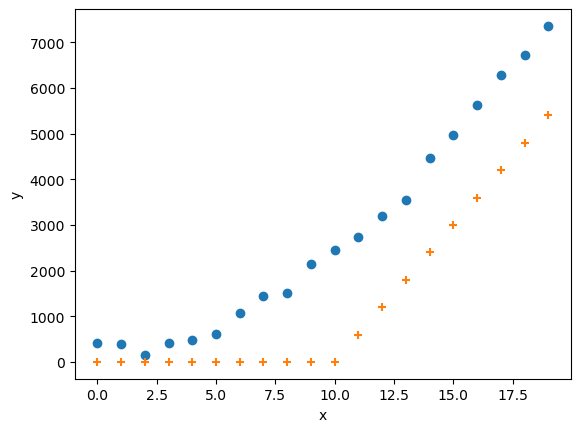

In [12]:
plot_model(x, y, NonLinearModel(600, -6000))

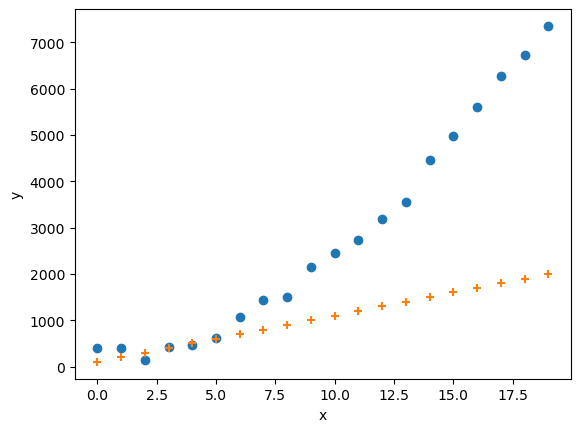

In [13]:
plot_model(x, y, NonLinearModel(100, 100))

Hier boven geeft hij alleen een goede voorspelling voor de eerste of tweede helft van de data. Als we deze twee modellen combineren krijgen we dit:

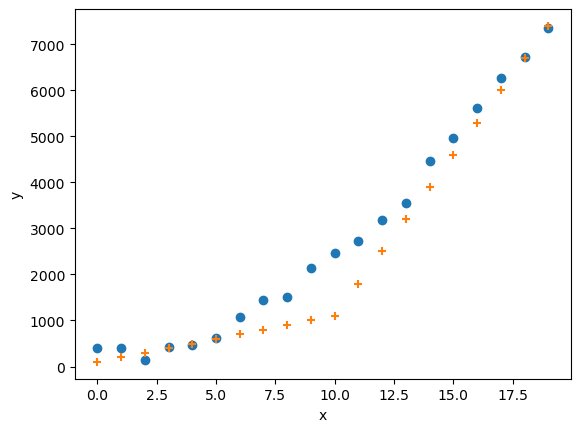

In [14]:
fig, ax = plt.subplots()
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.scatter(x, y)
ax.scatter(x, NonLinearModel(100, 100).forward(x) + NonLinearModel(600, -6000).forward(x), label='prediction', marker='+')
plt.show()

### Let there be light

En dit is hoe neurale netwerken worden geboren. Neurale netwerken in het nederlands: Een optel som van meerdere kleine non-lineaire vergelijkingen.

## Neurale netwerken trainen.

We gaan nu zo'n neuraal netwerk maken. Met meerdere van die nonlineaire modellen samen. Om die te kunnen trainen met gradient descent hebben we de afgeleide van de relu functie nodig. Aan jou om die te schrijven. Deze is net zoals de abs_d functie relatief eenvoudig en kijk vooral naar de vorm van de functie

### TODO: Programmeer relu_d

In [15]:
def relu_d(x):
    # TODO: Geef de afgeleide van de relu terug. Let op dat je een numpy array returned en geen enkel nummer.
    return np.where(x > 0, 1, 0)

relu_d_test = np.array([-10, -1, 0, 1, 2, 3, 4])
assert np.array_equal(relu_d(relu_d_test), np.array([0, 0, 0, 1, 1, 1, 1]))

Test je code door met de onderstaande cell de functie te visualiseren. Vraag jezelf af of dit klopt.

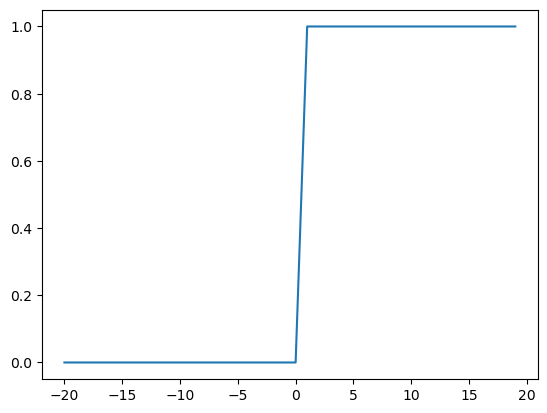

In [16]:
x_test = np.arange(-20, 20)
plt.plot(x_test, relu_d(x_test))
plt.show()

In [17]:
test_input = np.array([-2, -1, 0, 1, 2])
expected = np.array([0, 0, 0, 1, 1])  # Note: 0 at x=0 is conventional
result = relu_d(test_input)

assert np.array_equal(result, expected), f"Expected {expected}, got {result}"

# Test single elements
assert relu_d(np.array([5])) == np.array([1])
assert relu_d(np.array([-5])) == np.array([0])

# Test that it returns numpy array
assert isinstance(relu_d(np.array([1])), np.ndarray)
print("✓ Als dit print is het waarschijnlijk goed.")

✓ Als dit print is het waarschijnlijk goed.


## Into the matrix

We gaan nu dit combineren in een neuraal netwerk. Zo'n netwerk heeft een paar vaste elementen. De input layer, hidden layer en de output layer. De input layer is gewoon de data die we er in stoppen. De hidden layer dat zijn alle nonlineaire machientjes zoals we hierboven hebben gebruikt. De grootte van de hidden layer (het aantal neuronen/machientjes) is belangrijk. Stel we hebben een hidden_layer grootte van $30$, dan hebben we $30$ keer zo'n NonLinearModel. Elk van deze $30$ gebruikt dezelfde x als input, maar doet een andere berekenening op basis van de geleerde parameters.

Na de hidden layer, gaan de (bijvoorbeeld 30) outputs van alle machintjes door nog een laatste lineaire vergelijking, in ons geval om er weer één output van te maken. Dit is een gewogen som van alle NonLinearModel's. 

De code voor dit neuraal netwerk is gegeven. Aan jullie om dit te bestuderen en mee te experimenteren. In het volgende jaar gaan we dit zelf leren maken. Maar voor nu zijn er iets te veel variabelen en afgeleide om te berekenen, dat willen we jullie niet aan doen.

In [18]:
class NeuralNetwork:
    def __init__(self, hidden_size):
        # De hidden size is het aantal "neuronen" of "nonlinearmodels" in het netwerk
        self.hidden_size = hidden_size
        # Dit zijn de coefficienten van de hidden_layer, ofwel de a'tjes in ons LinearModel
        # We initialiseren het model met willekeurige nummers, dit helpt bij het trainen.
        self.w = np.random.normal(4,size=hidden_size).reshape(1,-1)
        # Dit zijn de biases van de hidden_layer, ofwel de b'tjes in ons LinearModel
        self.b = np.zeros((hidden_size))
        # Dit zijn de coefficienten van de output layer.
        self.w_output = np.random.normal(4, size=hidden_size).reshape(-1,1)

    def linear_pass(self, x):
        # Het Lineaire gedeelte
        # We gebruiken een matrix multiplicatie met @
        # Hierdoor kunnen we gemakkelijk veel lineaire vergelijkingen maken.
        return x @ self.w + self.b
    
    def forward(self, x):
        # Dit is een hele voorwaardse berekening van het netwerk
        # Nadat ons netwerk getraind is, dan is deze functie (en de linear_pass)
        # nog het enige wat we hoeven te gebruiken
        return relu(self.linear_pass(x)) @ self.w_output

    def grad_update(self, w, b, w_output):
        # Dit is een simpele functie om de gradient descent uit te voeren
        self.w -= w
        self.b -= b
        self.w_output -= w_output.reshape(-1,1) 

    # In de onderstaande drie functies berekenen we de afgeleide van onze 
    # parameters met betrekking tot elke neuron in de hidden layer
    def derrivative_w_input(self, x, neuron):
        return self.w_output[neuron] * relu_d(self.linear_pass(x))[neuron] * x

    def derrivative_b(self, x, neuron):
        return self.w_output[neuron] * relu_d(self.linear_pass(x))[neuron]
    
    def derrivative_w_output(self, x, neuron):
        return relu(self.linear_pass(x))[neuron]


def mae_d(x, y, model):
    # In deze functie (afgeleide van de MAE)
    # berekenen we voor m.b.t. alle parameters en alle neuronen
    # de gradients / afgeleide. Dit lijkt erg op wat je in deel 1 hebt gemaakt.
    y_predict = model.forward(x)
    gradient_w_input = []
    gradient_b_input = []
    gradient_w_output = []
    for neuron in range(model.hidden_size):
        gradient_w_input.append(np.sum(abs_d((y_predict) - y) 
                                   * model.derrivative_w_input(x, neuron)))
                       
        gradient_b_input.append(np.sum(abs_d((y_predict) - y) 
                                   * model.derrivative_b(x, neuron)))
                      
        gradient_w_output.append(np.sum(abs_d((y_predict) - y) 
                                 * model.derrivative_w_output(x, neuron), axis=0))
    return (np.array(gradient_w_input),
            np.array(gradient_b_input),
            np.array(gradient_w_output))
   



### TODO: Stel het netwerk in

De onderstaande twee cellen kun je gebruiken om het netwerk te trainen op onze data, en om te kijken hoe de MAE verandert. 

Aan jou de taak om het netwerk goed in te stellen. Verander de variabelen hidden_size, learning_rate en iterations tot je een goede fit en een lage MAE hebt.

Tips:
1. Hidden_size kan vast groter, meer neuronen meer beter?
2. Het model leert niet, je kunt kijken of de learning rate kleiner kan ? (veeel kleiner?)
3. Meer iteraties is altijd beter? Wanneer gaat de MAE niet meer om laag, en bij welke iteratie is MAE het laagste?
4. Met goede parameters kun je een heel mooie fit krijgen, en een lage MAE (lager dan 200?)

In [34]:
# Met deze getalletjes stellen we het neurale netwerk in
# dit noemen we ook wel de "hyperparameters"
# Hoeveelheid neuronen in de hidden layer
hidden_size = 10
# De learning rate
learning_rate = 0.001
# Het aantal keer dat we willen trainen over de hele dataset
iterations = 1000


# Hier onder hoef je niks aan te passen, mag natuurlijk wel.
# Initialiseer het netwerk
model = NeuralNetwork(hidden_size)
maes = []
for iter in range(iterations):
    for i in range(len(x)):
        # Voor elk datapunt in x voeren we backpropagation + gradient descent uit.
        # Backprop
        grad_w, grad_b, grad_w_ouput = mae_d(x[[i], 0], y[[i],0 ], model)
        # Gradient descent (inclusief een learning rate)
        model.grad_update(learning_rate  * grad_w,
                          learning_rate  * grad_b,
                          learning_rate  * grad_w_ouput)
    
    mae_it = mae(x, y, model)
    print(f'Iteration {iter} finished with MAE: {mae_it}')
    maes.append(mae_it)

plot_model(x, y, model)

Iteration 0 finished with MAE: 795.5710759500507
Iteration 1 finished with MAE: 671.3172886761313
Iteration 2 finished with MAE: 672.7982975331918
Iteration 3 finished with MAE: 680.2607866753216
Iteration 4 finished with MAE: 694.0508274679125
Iteration 5 finished with MAE: 708.086279379794
Iteration 6 finished with MAE: 722.6401541231965
Iteration 7 finished with MAE: 746.8773736736264
Iteration 8 finished with MAE: 771.5658693335232
Iteration 9 finished with MAE: 798.2282786405065
Iteration 10 finished with MAE: 840.5538423082417
Iteration 11 finished with MAE: 890.0248107775063
Iteration 12 finished with MAE: 789.0763718246478
Iteration 13 finished with MAE: 828.0165402269456
Iteration 14 finished with MAE: 877.5531962735101
Iteration 15 finished with MAE: 781.8996581462625
Iteration 16 finished with MAE: 816.3523579289193
Iteration 17 finished with MAE: 865.9672277869853
Iteration 18 finished with MAE: 917.3317942583762
Iteration 19 finished with MAE: 806.8396119912748
Iteration 2

KeyboardInterrupt: 

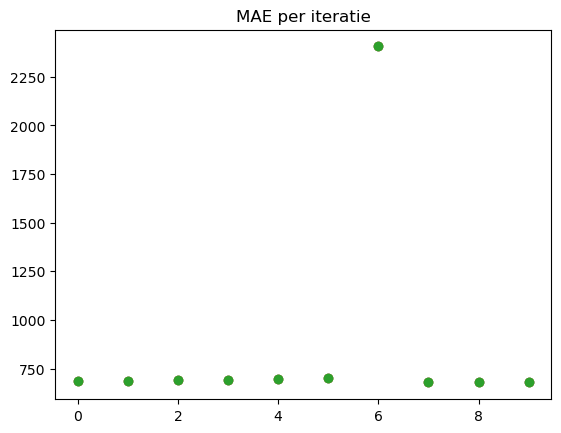

In [30]:
plt.title("MAE per iteratie")
plt.scatter(np.arange(len(maes)), maes)
plt.show()

## Vakantie!?

Heb je alles netjes gemaakt. Lever dan beide opdrachten in op brightspace. Succes met het tentamen en alvast een fijne vakantie!

## Grote Bonus opdracht!

In de NLP weken hebben we gewerkt met een fake-news dataset. Hieronder gaan we kijken of we daar een neuraal netwerk op kunnen trainen. Laten we eerste PyTorch installeren (https://pytorch.org/get-started/locally/), omdat we al genoeg afgeleide met de hand hebben berekent. PyTorch is een groot pakket die komt met veel afhankelijkheden, het installeren kan nog wel eens het nodige probleemoplossen vereisen.



In [21]:
#pip install torch torchvision torchaudio

Oke nu kunnen we een neuraal netwerk trainen. Eerst op onze test data van hier boven. Laten we direct 30 neuronen gebruiken in de hidden layer. PyTorch maakt gebruik van zijn eigen dataopslag, dus je moet numpy array converteren naar pytorch tensors. En als je weer wilt plotten doe je dit andersom.

In [22]:
import torch
import torch.nn as nn
import torch.optim as optim

# Define a simple neural network
class SimpleNet(nn.Module):
    def __init__(self, input_size=1, hidden_size=30, output_size=1):
        super(SimpleNet, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)
    
    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

# Create the model
model = SimpleNet()

# Define loss function and optimizer
criterion = nn.L1Loss() # MAE 
optimizer = optim.SGD(model.parameters(), lr=0.01)
# Als je wilt, deze is beter maar complexer dan dat we eerste deden
#optimizer = optim.Adam(model.parameters(), lr=0.1)

for iter in range(10000):

    # Forward pass
    output = model(torch.from_numpy(x).float())
    loss = criterion(output, torch.from_numpy(y).float()) # bereken de MAE

    # Backward pass
    optimizer.zero_grad() # Bereken de afgeleide functies
    loss.backward() # Bereken de backprop mbt de loss
    optimizer.step() # update de weights
    print(f'Iteration {iter} finished with MAE: {loss.item():.4f}')


Iteration 0 finished with MAE: 2800.3916
Iteration 1 finished with MAE: 2795.3242
Iteration 2 finished with MAE: 2790.2544
Iteration 3 finished with MAE: 2784.9980
Iteration 4 finished with MAE: 2779.3667
Iteration 5 finished with MAE: 2773.1616
Iteration 6 finished with MAE: 2766.1692
Iteration 7 finished with MAE: 2758.1479
Iteration 8 finished with MAE: 2748.8279
Iteration 9 finished with MAE: 2737.8923
Iteration 10 finished with MAE: 2724.9729
Iteration 11 finished with MAE: 2709.6360
Iteration 12 finished with MAE: 2691.3674
Iteration 13 finished with MAE: 2669.5542
Iteration 14 finished with MAE: 2643.4636
Iteration 15 finished with MAE: 2612.2275
Iteration 16 finished with MAE: 2574.8022
Iteration 17 finished with MAE: 2529.9385
Iteration 18 finished with MAE: 2476.1387
Iteration 19 finished with MAE: 2411.6057
Iteration 20 finished with MAE: 2334.1846
Iteration 21 finished with MAE: 2241.2915
Iteration 22 finished with MAE: 2130.4077
Iteration 23 finished with MAE: 2002.5934
It

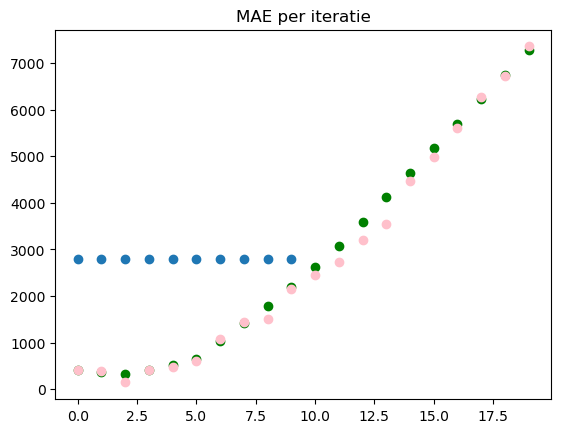

In [23]:
plt.scatter(x, output.detach(), color='green')
plt.scatter(x, y, color='pink')
plt.show()

Oefeningen op de code hierboven:
- Probeer de adam optimizer uit. Wat is de adam optimizer en wat is het verschil met stochastic gradient descent?
- Pas het aantal neuronen aan in de hidden laag, maakt het iets uit?
- Probeer een extra laag toe te voegen in het neurale netwerk


We zien dat het het best makkelijk is om een neuraal netwerk te trainen. Vooral als je weet wat de onderdelen doen. Laten we nu kijken of we het model kunnen trainen op de fake-news dataset

In [24]:
# Plaats hier je import en pipline om de fake-news dataset in te laten en ready te maken voor 
# een machine-learning model (zie vorige weken)
# zorg ervoor dat je x_train, y_train hebt dmv train test split.

Nu het lastige. We moeten het netwerk instellen voor onze data.
Todo:
- Stel de juiste input en output size in.
- Kijk of het netwerk traint, los eventuele problemen op. Het kan zijn dat er wat dingen moeten veranderen.
- Welke loss functie gebruik je voor classificatie? Nu staat er crossentropyloss, wat is dat?
- Voeg op het laatst nadat het netwerk getraint is een evaluatie toe aan de x_test, y_test set.

In [25]:
import torch
import torch.nn as nn
import torch.optim as optim

# Define a simple neural network
class SimpleNet(nn.Module):
    def __init__(self, input_size=1, hidden_size=30, output_size=1):
        super(SimpleNet, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)
    
    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

# Create the model
model = SimpleNet()

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss() 
optimizer = optim.Adam(model.parameters(), lr=0.1)

for iter in range(10000):

    # Forward pass
    output = model(torch.from_numpy(x_train).float())
    loss = criterion(output, torch.from_numpy(y_train).float())

    # Backward pass
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    print(f'Iteration {iter} finished with crossentropyloss: {loss.item():.4f}')


NameError: name 'x_train' is not defined